# Cuaderno 1 - Analisis descriptivo del conjunto de datos

**Objetivo:** conocer el conjunto de datos **Iris** que trae `scikit-learn` antes de entrenar cualquier modelo.

Este cuaderno responde a la pregunta: *que datos tengo y como se ven?*

> Importante: el analisis descriptivo **no entrena** nada. Solo describe, revisa calidad de datos y da a conocer las variables.
> Los nombres finales de las variables que obtengamos aqui son los que deben aparecer en el esquema Pydantic (`app/adapters/inbound/http/schemas.py`) de la API.

## 1. Importaciones y carga de datos

`load_iris(as_frame=True)` devuelve directamente un `DataFrame` de pandas, ideal para el analisis.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris

%matplotlib inline
pd.set_option("display.width", 120)

iris = load_iris(as_frame=True)

# Renombramos las columnas a snake_case: seran los nombres que espera la API.
df = iris.frame.rename(
    columns={
        "sepal length (cm)": "sepal_length",
        "sepal width (cm)": "sepal_width",
        "petal length (cm)": "petal_length",
        "petal width (cm)": "petal_width",
    }
)
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

FEATURES = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
TARGET = "species"

df.head()

,sepal_length,sepal_width,petal_length,petal_width,target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 2. Dimension, tipos y calidad de datos

Antes de modelar conviene responder: cuantos registros hay, de que tipo son las variables y si existen nulos o duplicados.

In [2]:
print(f"Registros: {df.shape[0]} | Variables: {df.shape[1]}")
df.info()

Registros: 150 | Variables: 6
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   target        150 non-null    int64  
 5   species       150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [3]:
print("Valores nulos por columna:")
print(df.isna().sum())
print()
print(f"Registros duplicados (sin contar la clase): {df[FEATURES].duplicated().sum()}")

Valores nulos por columna:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
target          0
species         0
dtype: int64

Registros duplicados (sin contar la clase): 1


**Observacion:** el conjunto no tiene valores nulos. Los registros duplicados (si aparecen) pueden ser flores distintas con la misma medida, por lo que no se eliminan en este ejemplo.

## 3. Estadistica descriptiva

`describe().T` transpone la tabla para leer una variable por fila: media, desviacion, minimos, maximos y cuartiles.

In [4]:
df[FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057,0.436,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758,1.765,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199,0.762,0.1,0.3,1.30,1.8,2.5


**Lectura de los rangos observados (se usaran como limites `ge`/`le` en la API):**

| Variable | Minimo | Maximo |
|---|---|---|
| sepal_length | 4.3 | 7.9 |
| sepal_width | 2.0 | 4.4 |
| petal_length | 1.0 | 6.9 |
| petal_width | 0.1 | 2.5 |

La desviacion estandar de `petal_length` (aprox. 1.77) es la mas alta: es la variable que mas varia entre flores.

## 4. Balance de la variable objetivo

Para un problema de clasificacion conviene revisar si las clases estan balanceadas.

In [5]:
conteo = df[TARGET].value_counts().sort_index()
print(conteo)
print()
print((conteo / len(df) * 100).round(2).astype(str) + " %")

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

species
setosa        33.33 %
versicolor    33.33 %
virginica     33.33 %
Name: count, dtype: str


**Observacion:** las tres especies tienen exactamente 50 registros (33.33 % cada una). El conjunto esta perfectamente balanceado, asi que la *accuracy* es una metrica interpretable.

## 5. Promedio de cada variable por especie

Si los promedios difieren mucho entre clases, el problema es separable y un modelo simple funcionara bien.

In [6]:
df.groupby(TARGET)[FEATURES].mean().round(3)

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


**Observacion:** `setosa` tiene petalos mucho mas cortos y angostos; `virginica` los tiene mas largos. Esto anticipa un modelo de clasificacion con buen desempeno.

## 6. Correlacion entre variables

Una correlacion alta entre dos variables de entrada indica redundancia (multicolinealidad).

In [7]:
correlaciones = df[FEATURES].corr()
correlaciones.round(3)

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000,-0.118,0.872,0.818
sepal_width,-0.118,1.000,-0.428,-0.366
petal_length,0.872,-0.428,1.000,0.963
petal_width,0.818,-0.366,0.963,1.000


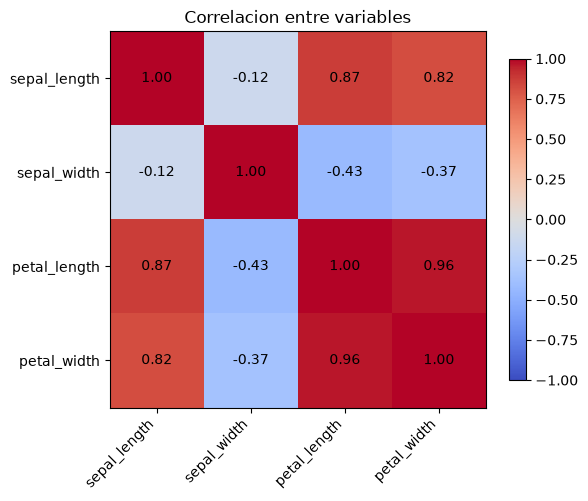

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
imagen = ax.imshow(correlaciones, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), labels=FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)), labels=FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{correlaciones.iloc[i, j]:.2f}", ha="center", va="center", color="black")
fig.colorbar(imagen, ax=ax, shrink=0.85)
ax.set_title("Correlacion entre variables")
fig.tight_layout()
plt.show()

**Observacion:** `petal_length` y `petal_width` tienen una correlacion muy alta (aprox. 0.96). Aportan informacion parecida, pero se conservan ambas porque el modelo las maneja bien y no hay problema de dimensionalidad.

## 7. Distribuciones (histogramas)

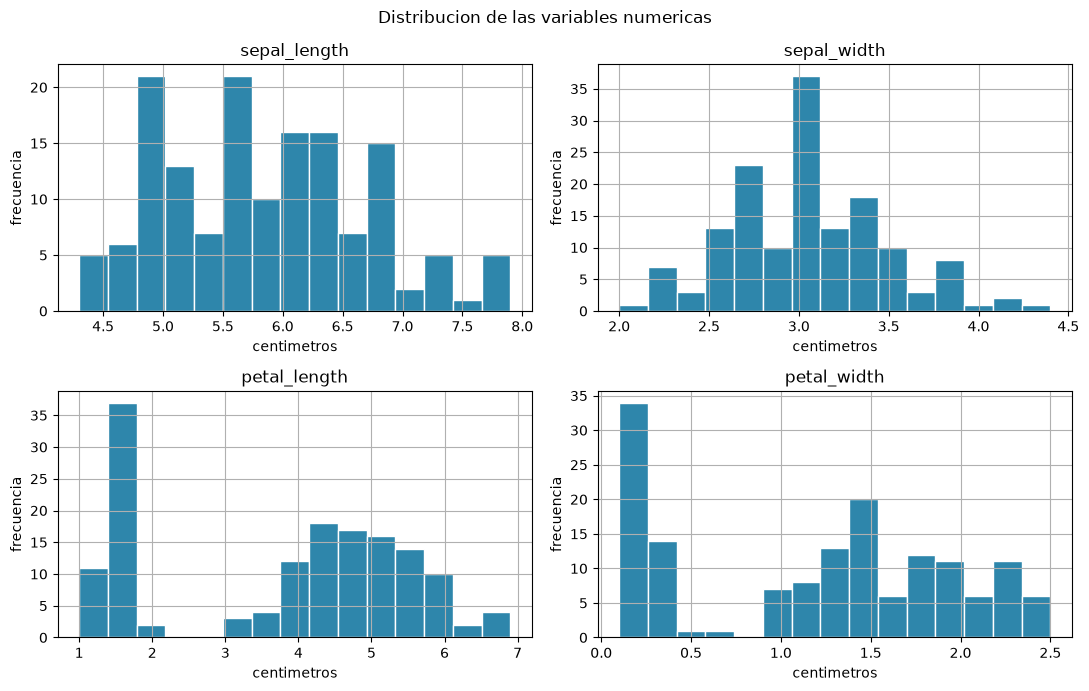

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, columna in zip(axes.ravel(), FEATURES):
    df[columna].hist(ax=ax, bins=15, color="#2E86AB", edgecolor="white")
    ax.set_title(columna)
    ax.set_xlabel("centimetros")
    ax.set_ylabel("frecuencia")
fig.suptitle("Distribucion de las variables numericas")
fig.tight_layout()
plt.show()

## 8. Diagramas de caja por especie

Los boxplots muestran la mediana y la dispersion de cada variable dentro de cada clase.

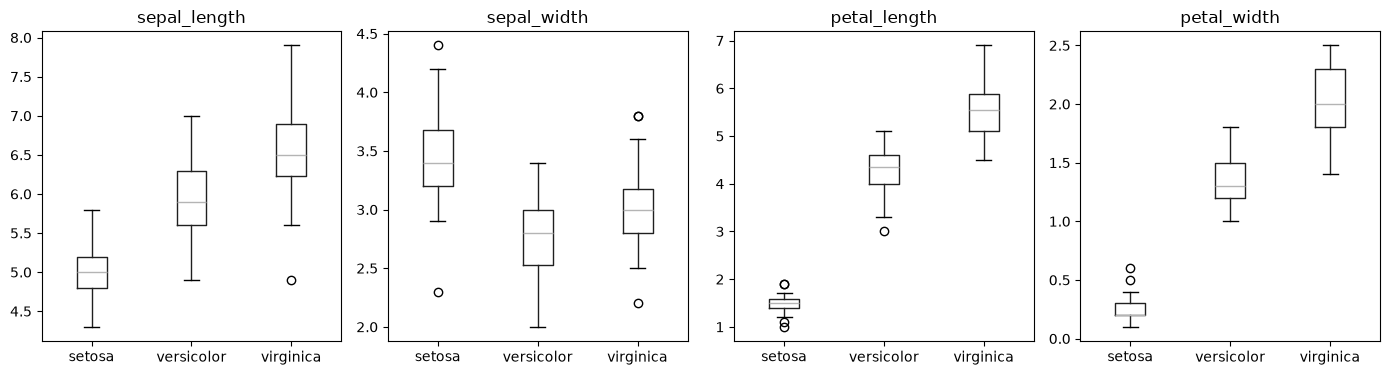

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, columna in zip(axes, FEATURES):
    df.boxplot(column=columna, by=TARGET, ax=ax, grid=False)
    ax.set_title(columna)
    ax.set_xlabel("")
fig.suptitle("")  # pandas agrega un titulo automatico que aqui no queremos
fig.tight_layout()
plt.show()

## 9. Dispersion: largo vs ancho del petalo

Esta es la vista clasica del problema: se ve de inmediato si las clases son separables.

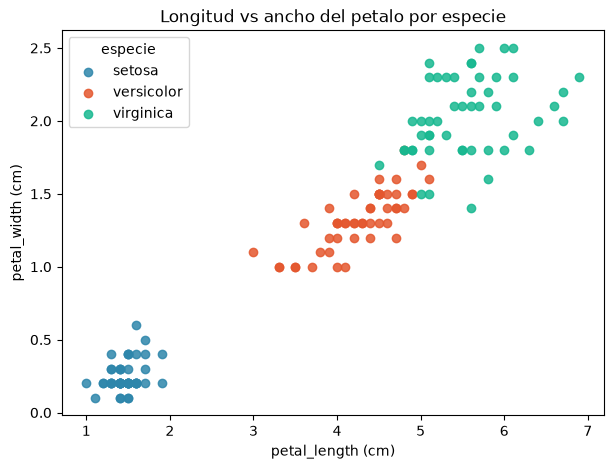

In [11]:
colores = {"setosa": "#2E86AB", "versicolor": "#E4572E", "virginica": "#17B890"}

fig, ax = plt.subplots(figsize=(7, 5))
for especie, grupo in df.groupby(TARGET):
    ax.scatter(
        grupo["petal_length"],
        grupo["petal_width"],
        label=especie,
        alpha=0.85,
        color=colores[especie],
    )
ax.set_xlabel("petal_length (cm)")
ax.set_ylabel("petal_width (cm)")
ax.set_title("Longitud vs ancho del petalo por especie")
ax.legend(title="especie")
plt.show()

**Observacion:** `setosa` queda claramente separada. `versicolor` y `virginica` se solapan un poco en la frontera, por lo que esperamos una exactitud alta pero no necesariamente perfecta.

## 10. Conclusiones del analisis descriptivo

1. El conjunto tiene **150 registros** y **4 variables numericas** de entrada mas la clase.
2. **No hay valores nulos**; no se requiere imputacion.
3. Las tres clases estan **balanceadas** (50 registros cada una).
4. Las variables estan en **escalas distintas** (0.1 cm hasta 7.9 cm), por lo que conviene **escalarlas** antes de un modelo lineal.
5. Las clases son **casi separables** con `petal_length` y `petal_width`.

### Contrato de variables que heredara la API

| # | Nombre en el modelo | Tipo | Rango observado |
|---|---|---|---|
| 1 | `sepal_length` | float | 4.3 - 7.9 |
| 2 | `sepal_width` | float | 2.0 - 4.4 |
| 3 | `petal_length` | float | 1.0 - 6.9 |
| 4 | `petal_width` | float | 0.1 - 2.5 |
| - | `species` (objetivo) | texto | setosa, versicolor, virginica |

**Siguiente paso:** `02_entrenamiento_modelo.ipynb`, donde se entrena y se guarda el modelo en `models/modelo.pkl`.